# Chart 4: Inflation-adjusted average annual increase in U.S. median household income

Article: <https://www.dailysignal.com/2026/09/30/real-story-gas-prices/> (Sanjai Bhagat, The Daily Signal, 30 Sep 2026).

Replicates the article's fourth chart: the average yearly change in real median household income over each administration. Cited source: U.S. Census Bureau, *Income in the United States: 2025* (P60-289). The numbers come from historical Table H-6, which gives median household income in 2025 dollars for every year since 1967.

Shared pieces live in two modules: `fetch_data.py` checks whether the local data is current and downloads it if not;
`charts.py` holds the styling, the administration windows and the chart helpers. The rendered PNG is written to `output/`.

## Data currency check

Only the sources this chart needs are checked. Stale or missing copies are downloaded; current ones are left alone.

In [1]:
import fetch_data

statuses = fetch_data.refresh(['census_h06'])

census_h06     current    latest=2025       fetched=2026-10-06T20:55:42+00:00


## Load the data

In [2]:
import polars as pl
import charts

income = fetch_data.load("census_h06")  # year, footnote, households_thousands, median/mean in current and real dollars
base_year = fetch_data._read_manifest().get("census_h06", {}).get("real_dollars_base_year") or int(income["year"].max())
print(f"{income['year'].min()} .. {income['year'].max()}  ({income.height} rows), real dollars base year {base_year}")
income.filter(pl.col("year") >= 2016)

1975 .. 2025  (53 rows), real dollars base year 2025


year,footnote,households_thousands,median_current_usd,median_real_usd,mean_current_usd,mean_real_usd
i64,i64,f64,f64,f64,f64,f64
2016,null,126200.0,59040.0,77230.0,83140.0,108800.0
2017,null,127600.0,61370.0,78900.0,86220.0,110800.0
2017,40,127700.0,61140.0,78600.0,87640.0,112700.0
2018,null,128600.0,63180.0,79620.0,90020.0,113400.0
2019,null,128500.0,68700.0,85320.0,98090.0,121800.0
…,…,…,…,…,…,…
2021,null,131200.0,70780.0,83270.0,102300.0,120400.0
2022,null,131400.0,74580.0,81460.0,106400.0,116200.0
2023,null,132200.0,80610.0,84730.0,114500.0,120400.0


## Windows and method

Each bar is `(median[last year] - median[year before first year]) / years`:

- Obama: 2008 to 2016, 8 years
- Trump 1.0: 2016 to 2020, 4 years
- Biden: 2020 to 2024, 4 years
- Trump 2.0: 2024 to 2025, 1 year

Where Census publishes two estimates for one year (2013 and 2017, after survey redesigns), the later methodology (the row with
the higher footnote number) is used. None of the endpoints above are affected.

In [3]:
WINDOWS = {"Obama": (2008, 2016), "Trump 1.0": (2016, 2020), "Biden": (2020, 2024), "Trump 2.0": (2024, 2025)}

median_real = (
    income.sort("year", "footnote", descending=[False, True], nulls_last=False)
          .unique(subset="year", keep="first", maintain_order=True)
          .select("year", "median_real_usd")
)
lookup = dict(zip(median_real["year"], median_real["median_real_usd"]))
increase = [(lookup[b] - lookup[a]) / (b - a) for a, b in WINDOWS.values()]
labels = [f"{k}\n({a + 1}-{b})" if b - a > 1 else f"{k}\n({b})" for k, (a, b) in WINDOWS.items()]

## Chart

administration,recomputed,article
str,i64,i64
"""Obama""",621,621
"""Trump 1.0""",1590,1590
"""Biden""",405,405
"""Trump 2.0""",2250,2250


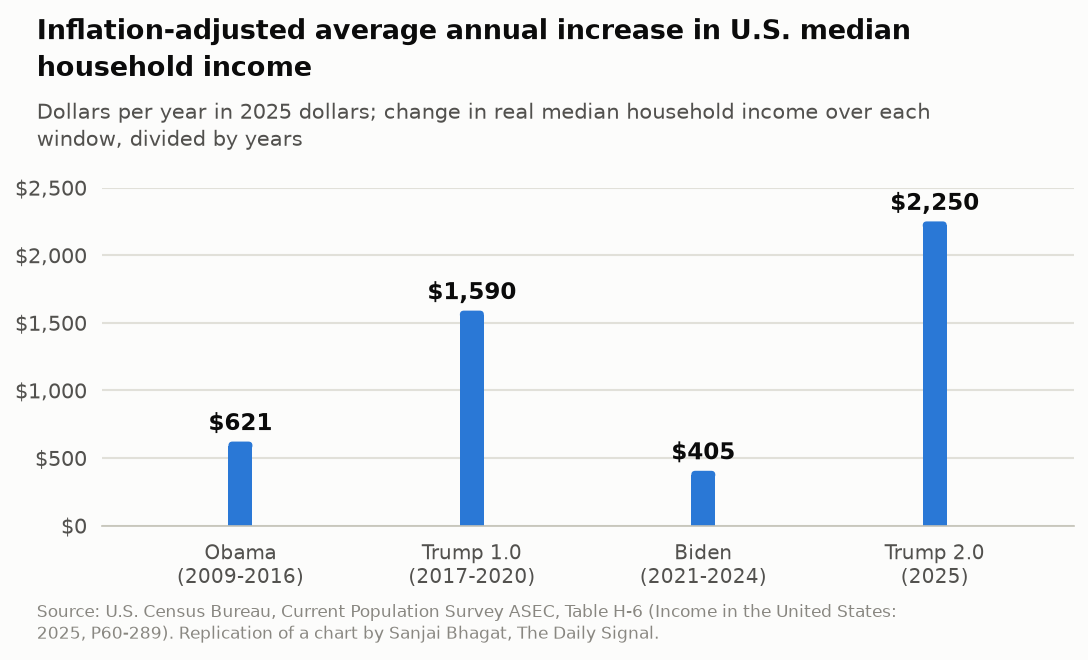

In [4]:
ARTICLE = [621, 1590, 405, 2250]

charts.bar_chart(
    labels, increase,
    title="Inflation-adjusted average annual increase in U.S. median household income",
    subtitle=f"Dollars per year in {base_year} dollars; change in real median household income over each window, divided by years",
    source="Source: U.S. Census Bureau, Current Population Survey ASEC, Table H-6 (Income in the United States: 2025, P60-289). Replication of a chart by Sanjai Bhagat, The Daily Signal.",
    fmt=lambda v: f"${v:,.0f}", ymax=2500, ystep=500, fname="04_income_increase.png",
)
charts.compare(WINDOWS, increase, ARTICLE, digits=0)

## Notes

Reproduces the article's $621, $1,590, $405 and $2,250 exactly. The article calls the quantity "household average annual income
increase"; the underlying statistic is the change in the *median* household's real income.